In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import torch
import torch.nn as nn
import shap
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DATA = Path("../data")

# Load the saved Ofsted arrays (from §6 of preprocessing.ipynb)
X_train = np.load(DATA / "X_cls_train.npy")
X_test  = np.load(DATA / "X_cls_test.npy")
y_test  = np.load(DATA / "y_cls_test.npy")

grade_labels = ["Inadequate", "Requires improvement", "Good", "Outstanding"]

# Correct feature names, in the order the pipeline outputs the columns
feature_names = list(np.load(DATA / "cls_feature_names.npy"))

class OfstedANN(nn.Module):
    def __init__(self, n_features=16, n_classes=4, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 32), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(32, 16),         nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(16, n_classes),
        )
    def forward(self, x): return self.net(x)

# Load the 5-seed ensemble
states = torch.load("../models/ofsted_ann.pt")
ensemble = []
for s in states:
    m = OfstedANN()
    m.load_state_dict(s)
    m.eval()
    ensemble.append(m)

print(f"Loaded {len(ensemble)} models. Test set: {X_test.shape}")
print("Features:", feature_names)

Loaded 5 models. Test set: (273, 16)
Features: [np.str_('fsm_pct_2024'), np.str_('imd_score'), np.str_('income_score'), np.str_('employment_score'), np.str_('barriers_score'), np.str_('living_env_score'), np.str_('idaci_score'), np.str_('adult_skills_score'), np.str_('geo_barriers_score'), np.str_('health_score'), np.str_('crime_score'), np.str_('wider_barriers_score'), np.str_('indoors_score'), np.str_('outdoors_score'), np.str_('p8_2023'), np.str_('a8_2024')]


In [2]:
# For classification, SHAP needs predicted PROBABILITIES, not just class labels
def predict_proba_fn(X_numpy):
    with torch.no_grad():
        X_t = torch.FloatTensor(X_numpy)
        return np.mean([torch.softmax(m(X_t), dim=1).numpy() for m in ensemble], axis=0)

# Background sample from training data (SHAP's reference distribution)
background = shap.sample(X_train, 100, random_state=SEED)

explainer = shap.KernelExplainer(predict_proba_fn, background)
print("SHAP explainer created.")
print(f"Baseline (expected class probabilities): {explainer.expected_value}")

SHAP explainer created.
Baseline (expected class probabilities): [0.09651475 0.18631651 0.46981739 0.24735135]


In [3]:
# Compute SHAP on a sample of test schools (full set is slow — 100 is plenty)
n_explain = 100
X_explain = X_test[:n_explain]
shap_values = explainer.shap_values(X_explain, nsamples=100)

# shap_values is a list of 4 arrays (one per class)
# OR a single 3D array (n_schools, n_features, n_classes) in newer SHAP versions
print(f"SHAP values type: {type(shap_values)}")
if isinstance(shap_values, list):
    print(f"List of {len(shap_values)} arrays, each shape: {shap_values[0].shape}")
else:
    print(f"Array shape: {shap_values.shape}")

  0%|          | 0/100 [00:00<?, ?it/s]

SHAP values type: <class 'numpy.ndarray'>
Array shape: (100, 16, 4)


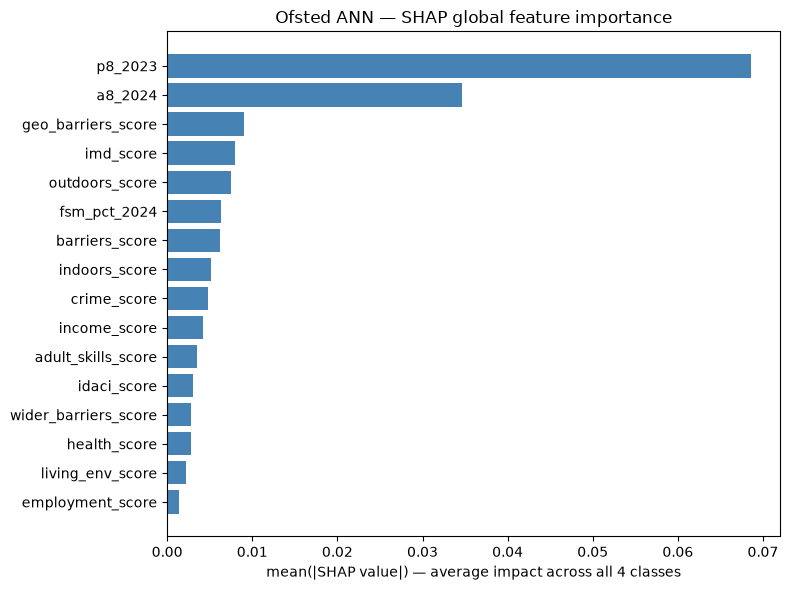


Top 5 features by SHAP importance:
           feature  mean_abs_shap
           p8_2023       0.068572
           a8_2024       0.034696
geo_barriers_score       0.009054
         imd_score       0.007952
    outdoors_score       0.007506


In [4]:
# Convert to 3D array if needed for consistent handling
if isinstance(shap_values, list):
    shap_array = np.stack(shap_values, axis=-1)  # (n_schools, n_features, n_classes)
else:
    shap_array = shap_values

# Mean absolute SHAP per feature across all classes
mean_abs_shap = np.abs(shap_array).mean(axis=(0, 2))
importance_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs_shap,
}).sort_values("mean_abs_shap", ascending=True)  # ascending for horizontal bar plot

plt.figure(figsize=(8, 6))
plt.barh(importance_df["feature"], importance_df["mean_abs_shap"], color="steelblue")
plt.xlabel("mean(|SHAP value|) — average impact across all 4 classes")
plt.title("Ofsted ANN — SHAP global feature importance")
plt.tight_layout()
plt.savefig("../SRC/EDA/fig_ofsted_shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nTop 5 features by SHAP importance:")
print(importance_df.sort_values("mean_abs_shap", ascending=False).head().to_string(index=False))

C:\Users\modne\AppData\Local\Temp\ipykernel_45732\2658478427.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


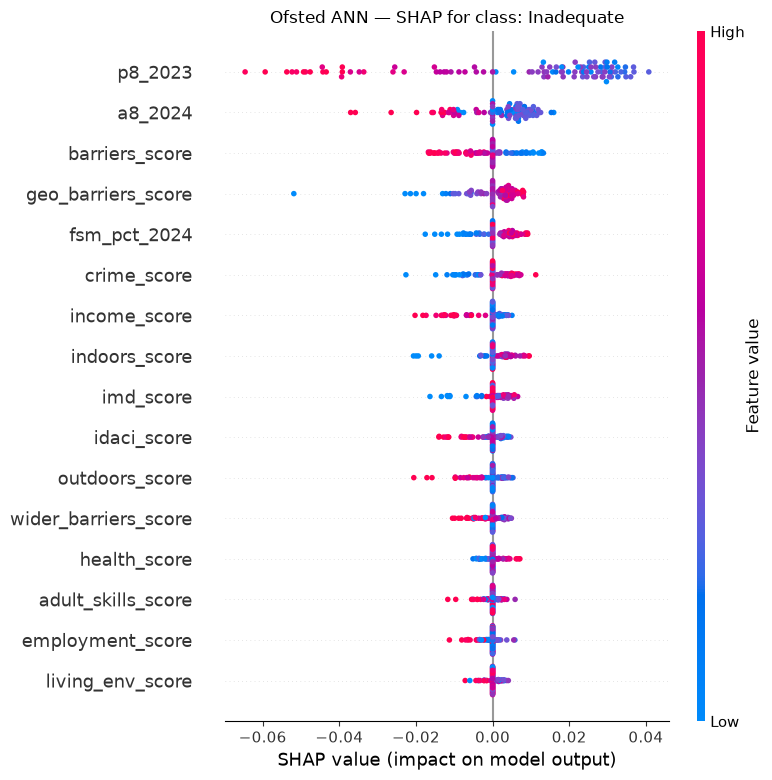

C:\Users\modne\AppData\Local\Temp\ipykernel_45732\2658478427.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


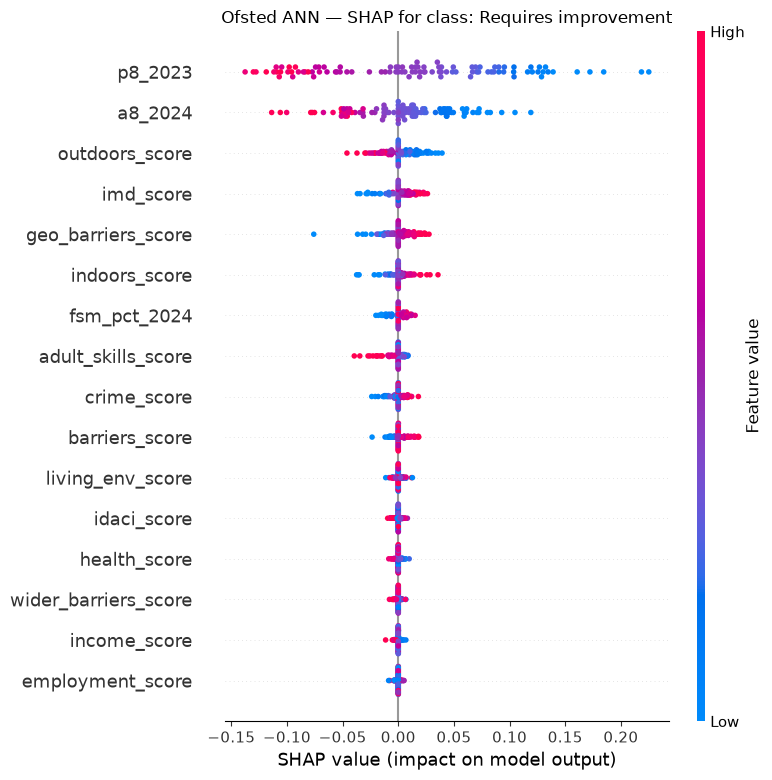

C:\Users\modne\AppData\Local\Temp\ipykernel_45732\2658478427.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


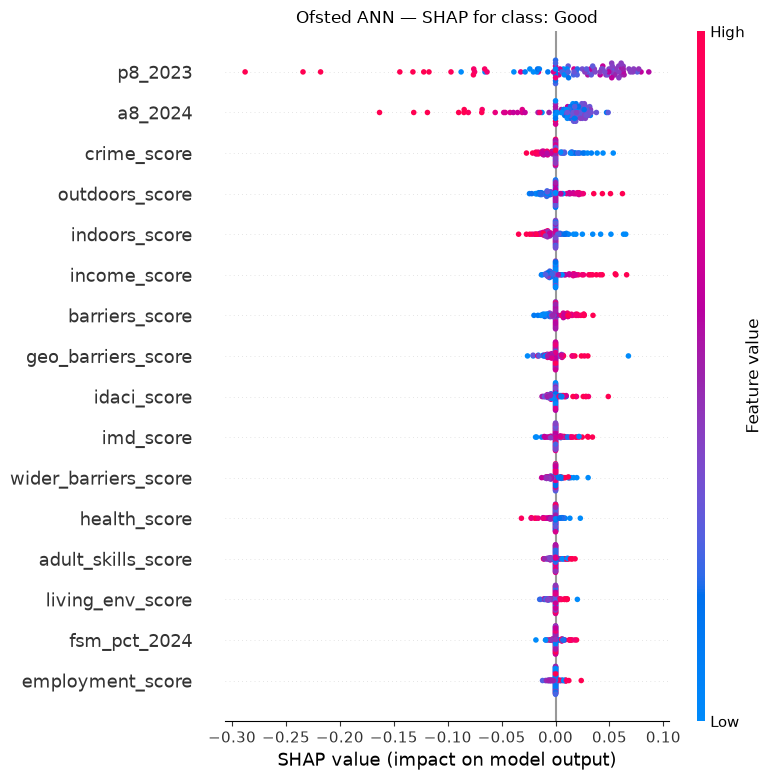

C:\Users\modne\AppData\Local\Temp\ipykernel_45732\2658478427.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


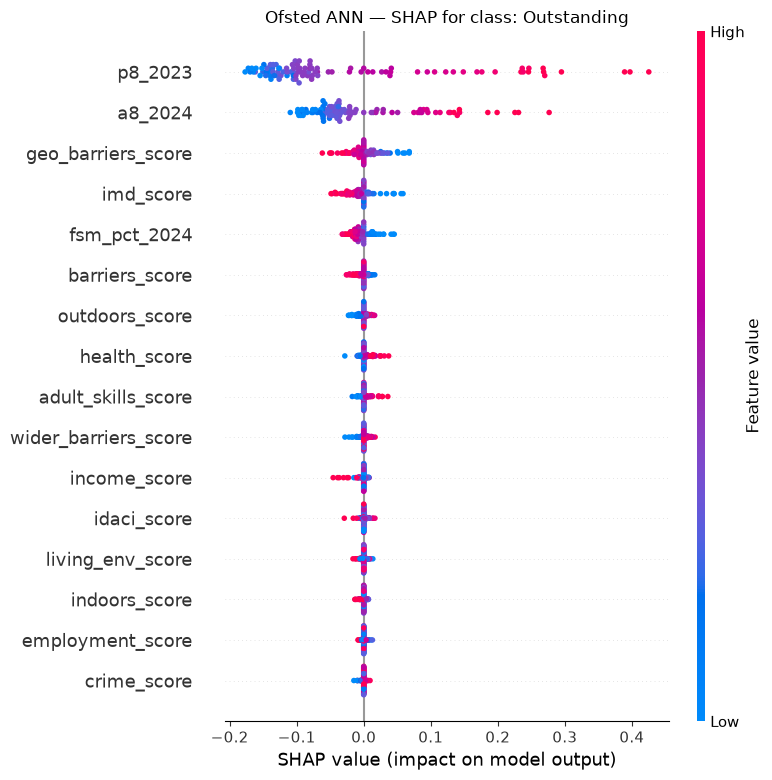

In [5]:
# Show SHAP contribution to each class separately
for class_idx, class_name in enumerate(grade_labels):
    # Get SHAP values for this specific class
    if isinstance(shap_values, list):
        class_shap = shap_values[class_idx]
    else:
        class_shap = shap_values[:, :, class_idx]

    shap.summary_plot(
        class_shap, X_explain,
        feature_names=feature_names,
        show=False,
        max_display=16,
    )
    plt.title(f"Ofsted ANN — SHAP for class: {class_name}")
    plt.tight_layout()
    safe_name = class_name.lower().replace(" ", "_")
    plt.savefig(f"../SRC/EDA/fig_ofsted_shap_beeswarm_{safe_name}.png",
                dpi=150, bbox_inches="tight")
    plt.show()

School #0:
  Actual class:    Good (2)
  Predicted class: Good (2)


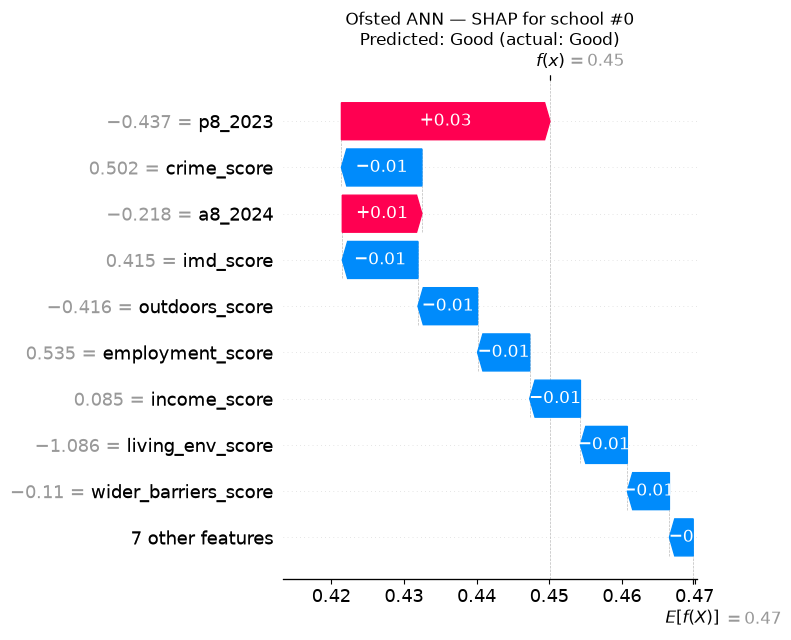

In [6]:
# Pick a specific school to explain — the first school in the explained set
school_idx = 0

# Predicted class from the ensemble (same prediction SHAP explains)
predicted_class = int(predict_proba_fn(X_explain[school_idx:school_idx+1]).argmax(axis=1)[0])
actual_class = int(y_test[school_idx])

print(f"School #{school_idx}:")
print(f"  Actual class:    {grade_labels[actual_class]} ({actual_class})")
print(f"  Predicted class: {grade_labels[predicted_class]} ({predicted_class})")

# Waterfall plot for the predicted class
if isinstance(shap_values, list):
    shap_for_class = shap_values[predicted_class][school_idx]
else:
    shap_for_class = shap_values[school_idx, :, predicted_class]
base_for_class = explainer.expected_value[predicted_class]

explanation = shap.Explanation(
    values=shap_for_class,
    base_values=base_for_class,
    data=X_explain[school_idx],
    feature_names=feature_names,
)

shap.waterfall_plot(explanation, show=False)
plt.title(f"Ofsted ANN — SHAP for school #{school_idx}\n"
          f"Predicted: {grade_labels[predicted_class]} (actual: {grade_labels[actual_class]})")
plt.tight_layout()
plt.savefig(f"../SRC/EDA/fig_ofsted_shap_waterfall_school{school_idx}.png",
            dpi=150, bbox_inches="tight")
plt.show()

In [7]:
print(feature_names)

[np.str_('fsm_pct_2024'), np.str_('imd_score'), np.str_('income_score'), np.str_('employment_score'), np.str_('barriers_score'), np.str_('living_env_score'), np.str_('idaci_score'), np.str_('adult_skills_score'), np.str_('geo_barriers_score'), np.str_('health_score'), np.str_('crime_score'), np.str_('wider_barriers_score'), np.str_('indoors_score'), np.str_('outdoors_score'), np.str_('p8_2023'), np.str_('a8_2024')]
